![Tutorial_banner](images/cbens_2026_performancetutorial_logo.jpg)

# Tutorial 3 — Dos dados de campo ao modelo: Simon Solar

**PV Performance Modeling in Practice — CBENS 2026**

**Objetivo:** explorar medições reais do PVDAQ, reconhecer padrões e lacunas e, depois, reproduzir a simulação PVWatts de **2016–2023** com um único arquivo meteorológico. Ao final, veremos **uma semana de potência AC medida e modelada**.

### Arquivos necessários
- `field_data/9069_subset_hourly.csv` — dados operacionais já agregados para a média horária, com horários marcados no **meio da hora (HH:30)**.
- `weather_data/Simon_Solar_NSRDB_2016_2023.csv` — dados históricos NSRDB já combinados, com séries horárias HH:30.

Execute as células em ordem. O notebook funciona no Jupyter local e no Colab **desde que os arquivos estejam nas mesmas pastas relativas ao notebook**.

## Parte A — Conhecendo os dados medidos

Antes de validar qualquer modelo, precisamos entender **o que foi medido**, a cobertura temporal e a qualidade aparente dos dados. Este arquivo reduzido conserva medidores AC, sensores meteorológicos e potência dos inversores.

**Atenção às unidades:** potência AC em `kW`; irradiância em `W/m²`; temperatura em `°C`. Cada ponto é a média das observações disponíveis em uma hora, **não** a soma das potências. Não substituímos valores ausentes por zero.

In [1]:
# Se necessário, no Google Colab: %pip install pvlib ipywidgets
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import ipywidgets as widgets
from IPython.display import display
from pathlib import Path
import pvlib

print("pvlib:", pvlib.__version__)

pvlib: 0.16.1


### Etapa A1 — Ler o arquivo horário

As datas foram exportadas com informação de fuso/offset. Para evitar ambiguidade na transição do horário de verão, lemos os instantes em UTC e os visualizamos no **horário padrão fixo UTC−5** (`Etc/GMT+5`), também utilizado pelos arquivos NSRDB deste exercício. Isto **não** altera a hora física de cada observação: apenas sua representação.

**Importante:** isso pressupõe que os offsets salvos no arquivo de campo estejam corretos. A origem dos timestamps do PVDAQ deve ser conferida antes de tirar conclusões sobre defasagens entre curvas.

In [14]:
field_file = Path("field_data/9069_subset_hourly.csv")
field = pd.read_csv(field_file)

time_col = "timestamp" if "timestamp" in field.columns else "utc_measured_on"
field[time_col] = pd.to_datetime(field[time_col], utc=True)
field = field.set_index(time_col).sort_index()
field.index = field.index.tz_convert("Etc/GMT+5")
field.index.name = "timestamp"
field = field.apply(pd.to_numeric, errors="coerce")

#field.index = field.index + pd.Timedelta(hours=4)


print("Período:", field.index.min(), "até", field.index.max())
print("Linhas:", len(field), "| Variáveis:", len(field.columns))
print("Intervalo típico:", field.index.to_series().diff().median())
print("Timestamps duplicados:", field.index.duplicated().sum())
display(field.head())

Período: 2016-02-17 17:30:00-05:00 até 2023-11-29 13:30:00-05:00
Linhas: 68205 | Variáveis: 54
Intervalo típico: 0 days 01:00:00
Timestamps duplicados: 0


,meter_1_ac_power_kw,meter_2_ac_power_kw,poa_irradiance_02a,poa_irradiance_02b,poa_irradiance_08,ghi_irradiance,reference_cell_poa_median,reference_cell_poa_1,module_temperature_median,ambient_temperature_median,...,inverter_33_ac_power_(kw),inverter_34_ac_power_(kw),inverter_35_ac_power_(kw),inverter_36_ac_power_(kw),inverter_37_ac_power_(kw),inverter_38_ac_power_(kw),inverter_39_ac_power_(kw),inverter_40_ac_power_(kw),meter_1_ac_power_kw_n_samples,meter_2_ac_power_kw_n_samples
timestamp,,,,,,,,,,,,,,,,,,,,,
2016-02-17 17:30:00-05:00,42.727273,NaN,16.878182,8.277273,6.236000,NaN,5.470000,-0.878182,7.837273,10.430000,...,1.527273,1.654545,1.736364,1.554545,1.872727,1.690909,1.727273,1.563636,NaN,NaN
2016-02-17 18:30:00-05:00,-60.000000,NaN,13.508333,6.565833,1.270000,NaN,0.375000,-5.672727,5.912500,8.680000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,NaN,NaN
2016-02-17 19:30:00-05:00,-60.000000,NaN,13.336667,4.600000,1.270000,NaN,0.310000,-5.766667,4.455000,6.710833,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,NaN,NaN
2016-02-17 20:30:00-05:00,-50.000000,NaN,12.478333,3.510000,1.270000,NaN,-0.015000,-6.236364,2.930000,5.477500,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,NaN,NaN
2016-02-17 21:30:00-05:00,-59.166667,NaN,12.369091,2.249091,1.098333,NaN,-0.469583,-5.766667,1.706667,4.235833,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,NaN,NaN


### Etapa A2 — Quais medições estão disponíveis?

Observe que existem **dois medidores AC** e numerosos canais de inversores. Não devemos somar ou substituir esses canais sem entender o esquema elétrico e os períodos em que cada um opera. Aqui começamos inspecionando os dois medidores.

In [15]:
meter_cols = [c for c in ["meter_1_ac_power_kw", "meter_2_ac_power_kw"] if c in field.columns]
inv_cols = [c for c in field.columns if c.startswith("inverter_") and "_ac_power_" in c]
weather_cols = [c for c in ["poa_irradiance_02a", "poa_irradiance_02b", "poa_irradiance_08", "ghi_irradiance", "reference_cell_poa_median", "module_temperature_median", "ambient_temperature_median", "wind_speed_ms"] if c in field.columns]

print("Medidores:", meter_cols)
print("Número de canais de potência dos inversores:", len(inv_cols))
print("Sensores selecionados:", weather_cols)
coverage = (field[meter_cols + weather_cols].notna().mean() * 100).round(1)
display(coverage.to_frame("Valores presentes (%)"))

Medidores: ['meter_1_ac_power_kw', 'meter_2_ac_power_kw']
Número de canais de potência dos inversores: 40
Sensores selecionados: ['poa_irradiance_02a', 'poa_irradiance_02b', 'poa_irradiance_08', 'ghi_irradiance', 'reference_cell_poa_median', 'module_temperature_median', 'ambient_temperature_median', 'wind_speed_ms']


,Valores presentes (%)
meter_1_ac_power_kw,33.6
meter_2_ac_power_kw,47.3
poa_irradiance_02a,36.8
poa_irradiance_02b,67.4
poa_irradiance_08,45.6
ghi_irradiance,43.1
reference_cell_poa_median,91.6
module_temperature_median,91.6
ambient_temperature_median,91.6
wind_speed_ms,43.1


### Etapa A3 — Visualizar **uma semana por vez**

O menu muda apenas o **intervalo apresentado**; o gráfico continua com pontos de **resolução horária**. Examine a forma das curvas diárias, quedas de potência, períodos ausentes e diferenças entre os medidores.

In [16]:
weeks = pd.date_range(
    field.index.min().tz_localize(None).to_period("W").start_time,
    field.index.max().tz_localize(None).to_period("W").start_time,
    freq="7D"
)
week_options = [(w.strftime("%Y-%m-%d"), w.strftime("%Y-%m-%d")) for w in weeks]

def plot_field_week(week):
    start = pd.Timestamp(week).tz_localize("Etc/GMT+5")
    end = start + pd.Timedelta(days=7)
    subset = field.loc[(field.index >= start) & (field.index < end), meter_cols]
    fig, ax = plt.subplots(figsize=(14, 4))
    for col in meter_cols:
        ax.plot(subset.index, subset[col] / 1000, label=col, linewidth=1)
    ax.set(title=f"Simon Solar — potência AC medida | semana de {week}",
           xlabel="Data (UTC−5)", ylabel="Potência AC média horária (MW)",
           xlim=(start, end))
    ax.set_ylim(bottom=0); ax.grid(alpha=.3); ax.legend()
    fig.autofmt_xdate(); plt.show()

widgets.interact(
    plot_field_week,
    week=widgets.Dropdown(options=week_options, description="Semana:")
);

interactive(children=(Dropdown(description='Semana:', options=(('2016-02-15', '2016-02-15'), ('2016-02-22', '2…

Horas somente M1: 22885
Horas somente M2: 32241
Horas com ambos: 0
Horas sem nenhum: 13079

Períodos de medição:
M1: 2016-02-17 17:30:00-05:00 até 2019-04-04 06:30:00-05:00
M2: 2020-03-26 05:30:00-05:00 até 2023-11-29 13:30:00-05:00


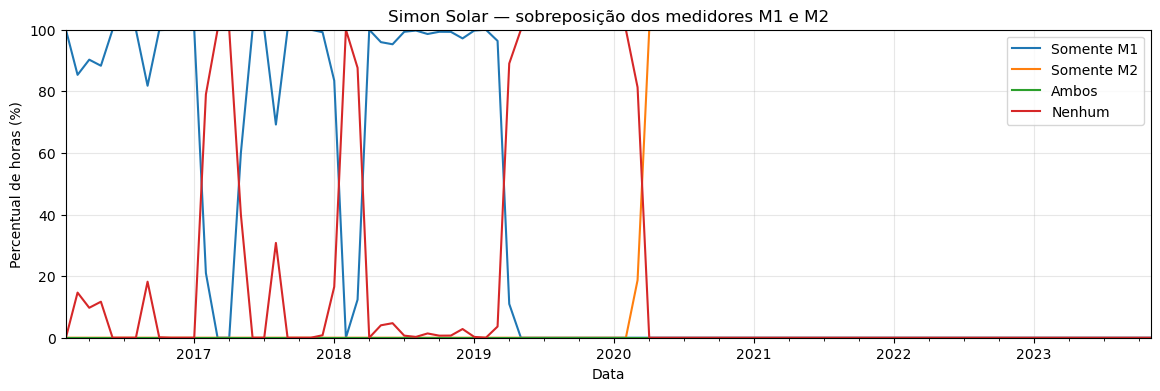

In [17]:
# ------------------------------------------
# SOBREPOSIÇÃO ENTRE MEDIDORES M1 E M2
# ------------------------------------------

m1 = field["meter_1_ac_power_kw"].notna()
m2 = field["meter_2_ac_power_kw"].notna()

overlap = pd.DataFrame({
    "Somente M1": m1 & ~m2,
    "Somente M2": m2 & ~m1,
    "Ambos": m1 & m2,
    "Nenhum": ~m1 & ~m2
}, index=field.index)

# Resumo
print("Horas somente M1:", overlap["Somente M1"].sum())
print("Horas somente M2:", overlap["Somente M2"].sum())
print("Horas com ambos:", overlap["Ambos"].sum())
print("Horas sem nenhum:", overlap["Nenhum"].sum())

print("\nPeríodos de medição:")
for meter, mask in [("M1", m1), ("M2", m2)]:
    if mask.any():
        dates = field.index[mask]
        print(f"{meter}: {dates.min()} até {dates.max()}")

# Disponibilidade mensal (% das horas)
monthly_overlap = overlap.resample("MS").mean() * 100

ax = monthly_overlap.plot(
    figsize=(14, 4),
    title="Simon Solar — sobreposição dos medidores M1 e M2"
)

ax.set_ylabel("Percentual de horas (%)")
ax.set_xlabel("Data")
ax.set_ylim(0, 100)
ax.grid(alpha=0.3)
plt.show()

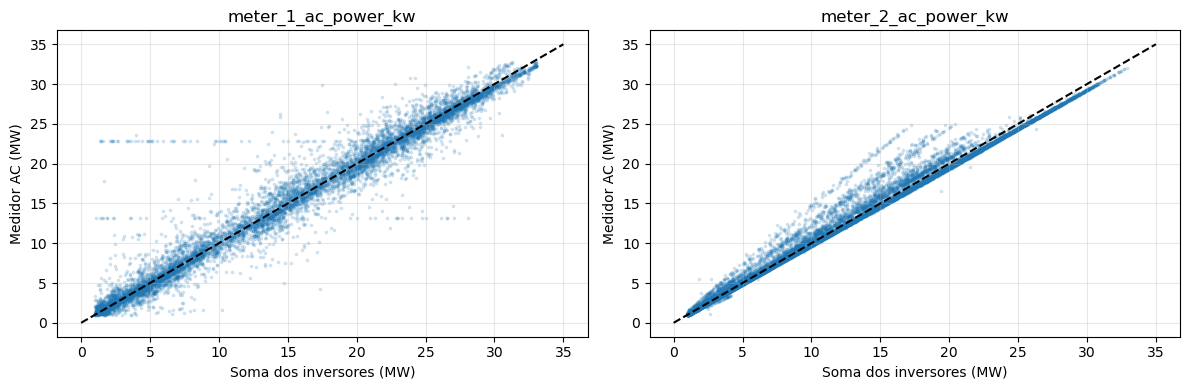

In [18]:
# Soma da potência dos 40 inversores
inv_cols = [
    c for c in field.columns
    if c.startswith("inverter_") and "_ac_power_" in c
    and "power_factor" not in c
]

field["inverter_total_kw"] = field[inv_cols].sum(
    axis=1, min_count=len(inv_cols)
)

# Comparar cada medidor com a soma dos inversores
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

for ax, meter in zip(axes, meters):
    subset = field[[meter, "inverter_total_kw"]].dropna()
    subset = subset[(subset[meter] > 1000) & (subset["inverter_total_kw"] > 1000)]

    ax.scatter(subset["inverter_total_kw"] / 1000,
               subset[meter] / 1000, s=3, alpha=0.15)
    ax.plot([0, 35], [0, 35], "k--")
    ax.set(xlabel="Soma dos inversores (MW)",
           ylabel="Medidor AC (MW)", title=meter)
    ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()

### Etapa A4 — Irradiância e potência: comportamento esperado

Vamos examinar, para uma semana, um canal de irradiância POA junto à potência do medidor. Os eixos têm unidades diferentes: **compare a forma**, não diretamente a altura das curvas. É normal a potência depender também da temperatura, das perdas e da disponibilidade dos equipamentos.

In [19]:
# Combinar M1 e M2 (sem somar)
field["ac_power_kw"] = field["meter_2_ac_power_kw"].combine_first(field["meter_1_ac_power_kw"])
poa_col = "poa_irradiance_02a"

def plot_field_poa_week(week):
    start = pd.Timestamp(week).tz_localize("Etc/GMT+5")
    subset = field.loc[start:start + pd.Timedelta(days=7) - pd.Timedelta(seconds=1)]

    fig, ax = plt.subplots(figsize=(14, 4))
    ax.plot(subset.index, subset["ac_power_kw"] / 1000, label="Potência AC", color="tab:blue")
    ax.set(ylabel="Potência AC (MW)", ylim=(0, None),
           title=f"Potência AC e POA — semana de {week}", xlabel="Data (UTC−5)")

    ax2 = ax.twinx()
    ax2.plot(subset.index, subset[poa_col], color="tab:orange", alpha=0.7)
    ax2.set(ylabel="POA (W/m²)", ylim=(0, None))

    ax.grid(alpha=0.3)
    fig.autofmt_xdate()
    lines1, labels1 = ax.get_legend_handles_labels()
    lines2, labels2 = ax2.get_legend_handles_labels()
    ax.legend(lines1 + lines2, labels1 + labels2, loc="upper right")
    plt.show()

widgets.interact(
    plot_field_poa_week,
    week=widgets.Dropdown(options=week_options, description="Semana:")
);

interactive(children=(Dropdown(description='Semana:', options=(('2016-02-15', '2016-02-15'), ('2016-02-22', '2…

### Etapa A5 — Cobertura mensal das medições

O percentual abaixo mostra a **fração de horas com valor registrado**, e não a disponibilidade física da usina. Um medidor pode ter dados ausentes por problemas de comunicação, e o valor zero pode ser uma observação legítima. Mais tarde, no QA/QC, distinguiremos essas situações.

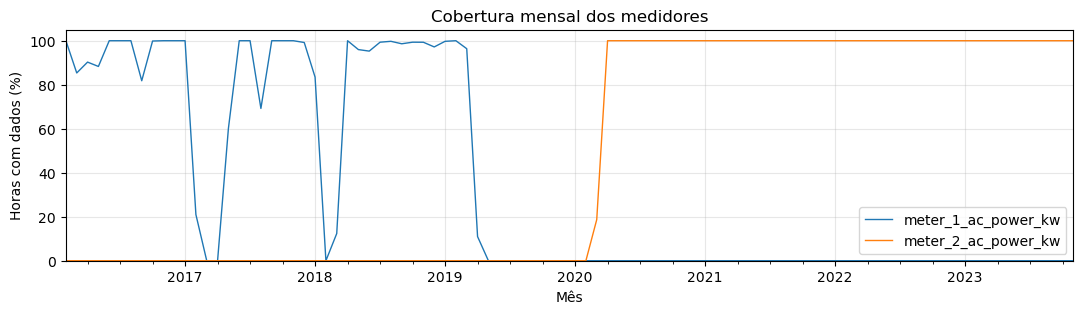

In [20]:
monthly_coverage = field[meter_cols].notna().resample("MS").mean() * 100
ax = monthly_coverage.plot(figsize=(13, 3), linewidth=1)
ax.set(title="Cobertura mensal dos medidores", ylabel="Horas com dados (%)", xlabel="Mês", ylim=(0, 105))
ax.grid(alpha=.3); plt.show()

### Discussão rápida

- Em quais semanas você identifica curvas solares regulares? Há semanas com dados ausentes?
- O que pode explicar dias com POA positiva e potência AC igual a zero?
- Qual medidor parece ter dados adequados para comparação com um **modelo da usina inteira**? Como você confirmaria o significado desse canal?
- Por que não devemos preencher automaticamente todas as lacunas com zero?

In [21]:
# Combinar M1 e M2 em um único canal de potência AC
field["meter_ac_power_kw"] = field["meter_1_ac_power_kw"].combine_first(
    field["meter_2_ac_power_kw"]
)

## Parte B — Simular 2016–2023 e comparar uma semana

Nesta parte executamos **o mesmo fluxo físico** do Tutorial 2, agora em todos os anos do arquivo NSRDB combinado:

**GHI/DNI/DHI → posição solar → POA → temperatura da célula → potência DC (PVWatts) → perdas → inversor PVWatts → potência AC**.

Não introduzimos ainda degradação progressiva, indisponibilidade de inversores nem calibração pelos dados de campo. Queremos primeiro comparar um modelo-base com a realidade.

### Etapa B1 — Ler o arquivo meteorológico combinado

Este CSV foi salvo previamente com `pandas`, por isso usamos `pd.read_csv()` — não o leitor de arquivos PSM4 originais. Verifique especialmente os horários `HH:30`, o fuso e as colunas exigidas.

In [22]:
weather_file = Path("weather_data/Simon_Solar_NSRDB_2016_2023.csv")
weather = pd.read_csv(weather_file)
weather["timestamp"] = pd.to_datetime(weather["timestamp"], utc=True)
weather = weather.set_index("timestamp").sort_index()
weather.index = weather.index.tz_convert("Etc/GMT+5")
weather.index.name = "timestamp"

needed = ["ghi", "dni", "dhi", "temp_air", "wind_speed"]
missing = [c for c in needed if c not in weather.columns]
if missing:
    raise ValueError(f"Colunas meteorológicas ausentes: {missing}")

print("Período:", weather.index.min(), "até", weather.index.max())
print("Intervalo típico:", weather.index.to_series().diff().median())
print("Minutos observados:", sorted(weather.index.minute.unique()))
display(weather[needed].head())

Período: 2016-01-01 00:30:00-05:00 até 2023-12-31 23:30:00-05:00
Intervalo típico: 0 days 01:00:00
Minutos observados: [30]


,ghi,dni,dhi,temp_air,wind_speed
timestamp,,,,,
2016-01-01 00:30:00-05:00,0.0,0.0,0.0,8.8,0.5
2016-01-01 01:30:00-05:00,0.0,0.0,0.0,8.3,0.5
2016-01-01 02:30:00-05:00,0.0,0.0,0.0,7.7,0.5
2016-01-01 03:30:00-05:00,0.0,0.0,0.0,7.0,0.5
2016-01-01 04:30:00-05:00,0.0,0.0,0.0,6.3,0.5


### Etapa B2 — Executar o modelo completo (célula fornecida)

No Tutorial 2 vocês construíram as etapas individualmente. Aqui reunimos essas mesmas etapas em uma só célula para dedicar mais tempo à análise dos dados de campo.

**Hipóteses iniciais:** capacidade DC de 38,6 MW, coeficiente térmico equivalente −0,42%/°C, estrutura fixa com 20°/180°, albedo constante de 0,20, perdas agregadas de 9,867% e eficiência nominal de inversor de 96%. Sem sombreamento entre fileiras explícito, sem degradação temporal e sem perdas de disponibilidade variáveis no tempo.

A equação DC usada é a de `pvlib.pvsystem.pvwatts_dc` (não uma simulação elétrica de cada string).

In [23]:
# Parâmetros da usina — mesmo caso-base do Tutorial 2
latitude, longitude = 33.6762, -83.67633
surface_tilt, surface_azimuth = 20, 180
albedo = 0.20
pdc0 = 38_600_000        # Wdc
gamma_pdc = -0.0042      # 1/°C
dc_ac_ratio = 1.17
eta_inv_nom = 0.96
baseline_losses = 9.867  # %

location = pvlib.location.Location(latitude, longitude, tz="Etc/GMT+5", name="Simon Solar")
solar_position = location.get_solarposition(weather.index)

poa = pvlib.irradiance.get_total_irradiance(
    surface_tilt=surface_tilt,
    surface_azimuth=surface_azimuth,
    solar_zenith=solar_position["apparent_zenith"],
    solar_azimuth=solar_position["azimuth"],
    dni=weather["dni"], ghi=weather["ghi"], dhi=weather["dhi"],
    albedo=albedo, model="isotropic"
)

temp_params = pvlib.temperature.TEMPERATURE_MODEL_PARAMETERS["sapm"]["open_rack_glass_glass"]
cell_temperature = pvlib.temperature.sapm_cell(
    poa_global=poa["poa_global"],
    temp_air=weather["temp_air"],
    wind_speed=weather["wind_speed"],
    **temp_params
)

pdc = pvlib.pvsystem.pvwatts_dc(
    effective_irradiance=poa["poa_global"],
    temp_cell=cell_temperature,
    pdc0=pdc0,
    gamma_pdc=gamma_pdc
)
pdc_after_losses = pdc * (1 - baseline_losses / 100)
pac_nominal = pdc0 / dc_ac_ratio
inverter_pdc0 = pac_nominal / eta_inv_nom
pac = pvlib.inverter.pvwatts(
    pdc_after_losses,
    pdc0=inverter_pdc0,
    eta_inv_nom=eta_inv_nom
)

modeled = pd.DataFrame({
    "poa_global_wm2": poa["poa_global"],
    "cell_temperature_c": cell_temperature,
    "dc_power_w": pdc,
    "ac_power_kw": pac / 1000,
}, index=weather.index)

display(modeled.head())
print("Horas modeladas com valor AC:", modeled["ac_power_kw"].notna().sum())

,poa_global_wm2,cell_temperature_c,dc_power_w,ac_power_kw
timestamp,,,,
2016-01-01 00:30:00-05:00,0.0,8.8,0.0,0.0
2016-01-01 01:30:00-05:00,0.0,8.3,0.0,0.0
2016-01-01 02:30:00-05:00,0.0,7.7,0.0,0.0
2016-01-01 03:30:00-05:00,0.0,7.0,0.0,0.0
2016-01-01 04:30:00-05:00,0.0,6.3,0.0,0.0


Horas modeladas com valor AC: 70080


### Etapa B3 — Uma semana: potência medida × modelada

Agora vamos usar o mesmo seletor semanal para sobrepor a potência AC prevista e o medidor de campo escolhido. **Ambas as curvas estão em MW**, em instantes correspondentes ao centro da hora.

Começamos pelo `meter_2_ac_power_kw`, usado no estudo anterior. Isso **não garante** que o medidor representa toda a usina em todos os períodos; os dados e o diagrama elétrico precisam ser confirmados. Também é necessário verificar a convenção original dos timestamps do PVDAQ antes de interpretar defasagens como erro do modelo.

In [24]:
comparison_meter = "meter_2_ac_power_kw"
if comparison_meter not in field:
    raise KeyError(f"Medidor não encontrado: {comparison_meter}")

comparison = pd.concat([
    (modeled["ac_power_kw"] / 1000).rename("Modelado (MW)"),
    (field[comparison_meter] / 1000).rename("Medido (MW)")
], axis=1).sort_index()

# Somente semanas em que há pelo menos um ponto medido e modelado
both_present = comparison.dropna()
if both_present.empty:
    raise ValueError("Não há timestamps coincidentes com potência medida e modelada. Verifique fusos/horários e cobertura dos arquivos.")

compare_weeks = pd.date_range(
    both_present.index.min().tz_localize(None).to_period("W").start_time,
    both_present.index.max().tz_localize(None).to_period("W").start_time,
    freq="7D"
)
compare_options = [(w.strftime("%Y-%m-%d"), w.strftime("%Y-%m-%d")) for w in compare_weeks]

def plot_comparison_week(week):
    start = pd.Timestamp(week).tz_localize("Etc/GMT+5")
    end = start + pd.Timedelta(days=7)
    subset = comparison.loc[(comparison.index >= start) & (comparison.index < end)]
    ax = subset.plot(figsize=(14, 4), linewidth=1.1)
    ax.set(title=f"Simon Solar — potência AC medida e modelada | {week}",
           ylabel="Potência AC (MW)", xlabel="Data (UTC−5)", xlim=(start, end))
    ax.set_ylim(bottom=0); ax.grid(alpha=.3)
    plt.show()
    print("Pontos horários coincidentes nesta semana:", subset.dropna().shape[0])

widgets.interact(
    plot_comparison_week,
    week=widgets.Dropdown(options=compare_options, description="Semana:")
);

interactive(children=(Dropdown(description='Semana:', options=(('2020-03-23', '2020-03-23'), ('2020-03-30', '2…


## Investigação: por que as curvas não coincidem?

Observe os horários dos picos de potência medida e modelada. As curvas apresentam um deslocamento sistemático, mesmo quando seus perfis são semelhantes.

**Será que o problema está no modelo ou na interpretação dos timestamps?**

Os dados meteorológicos NSRDB utilizam UTC−5, com registros no centro de cada hora (HH:30). Entretanto, os timestamps do arquivo PVDAQ podem ter recebido uma identificação incorreta de fuso horário durante a preparação dos dados.

### Vamos investigar!

1. Compare os horários de geração nas duas curvas. Qual parece ser o deslocamento?
2. Volte à célula inicial de carregamento dos dados de campo (`field`).
3. Experimente adicionar, **após a conversão para UTC−5**, a seguinte linha:

   `field.index = field.index + pd.Timedelta(hours=4)`

4. Execute novamente as células seguintes e observe o gráfico de comparação.

**Discussão:** A concordância melhorou? Isso significa que identificamos a causa do problema?

**Importante:** O deslocamento de 4 horas é uma correção *experimental*, identificada pela comparação dos dados, e não uma confirmação de que o relógio original estava errado. Em uma análise real, devemos verificar os timestamps na fonte antes de adotar a correção definitivamente.


## Encerramento — Preparação para a próxima atividade

Até aqui, construímos uma comparação **visual** sem ajustar o modelo e sem remover dados. Na próxima atividade, os grupos irão:

- Investigar diferenças entre o modelado e o medido e selecionar intervalos de interesse;
- Realizar QA/QC dos sinais e decidir quais horas devem entrar na comparação;
- Calcular **MBE, MAE, RMSE** e outras métricas, com atenção à normalização e às unidades;
- Examinar hipóteses de perdas, temperatura, disponibilidade e parâmetros incertos — distinguindo ajustes físicos de simples *fitting*.

**Pergunta final:** quando uma curva modelada se afasta da medida, estamos diante de um problema do modelo, dos dados meteorológicos, do sensor, do horário ou da própria operação da usina?

In [25]:
from pathlib import Path


# Salvar resultados para o Tutorial 4
output_dir = Path("results")
output_dir.mkdir(exist_ok=True)

modeled.to_csv(
    output_dir / "Simon_Solar_modeled_2016_2023.csv",
    index_label="timestamp"
)

field.to_csv(
    output_dir / "Simon_Solar_field_aligned_2016_2023.csv",
    index_label="timestamp"
)

print("Arquivos salvos:")
print(output_dir / "Simon_Solar_modeled_2016_2023.csv")
print(output_dir / "Simon_Solar_field_aligned_2016_2023.csv")

Arquivos salvos:
results\Simon_Solar_modeled_2016_2023.csv
results\Simon_Solar_field_aligned_2016_2023.csv
